In [1]:
# import sympy
from sympy import (symbols, expand, Rational, init_printing, sqrt, cos, sin,
                   init_printing, pprint, simplify, factor, trigsimp, collect,
                   cancel, powsimp, expand_power_exp, powdenest)
init_printing()

x, y, z = symbols("x y z")

expr = x + 2*y
e2 = 3*x + y**2
e3 = expr*e2*z
e4 = expand(e3)
# # print(e3)
# e4
# print((cos(x)+2).subs(cos(x), 3))


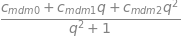

In [3]:
"""Calculations for m^-"""
x_0, y_0, theta0, x_c, y_c, r_c, rho, x_f, y_f, q = symbols(
    "x_0, y_0, theta0, x_c, y_c, r_c, rho, x_f, y_f, q")

R = r_c + rho
# print(R)

c_0x = x_0 - rho*sin(theta0)
c_0y = y_0 + rho*cos(theta0)

cos1 = (1 - q**2)/(1 + q**2)
sin1 = 2*q/(1 + q**2)

c_1x = x_c - R*sin1
c_1y = y_c + R*cos1

# m_minus_x and m_minus_y are MOST DEFINITELY NOT THE RIGHT VALUES HERE.
# I will need to look at how to make it all work. Maybe start from the end
# (end = developed theorem) and work towards the beginning?

m_minus_x = c_1x - c_0x
m_minus_x = collect(factor(m_minus_x), q)
m_minus_y = c_1y - c_0y
m_minus_y = collect(factor(m_minus_y),q)
# print("m_minus_x =", m_minus_x)
# print("m_minus_y =", m_minus_y)

m_d_minus = factor(m_minus_x**2 + m_minus_y**2)
m_d_minus = collect(m_d_minus, q)

# Simplify m_d_minus by regrouping some constant terms into subterms
m_d_minus_numer, m_d_minus_denom = m_d_minus.as_numer_denom()
# m_d_minus_numer
# m_d_minus_denom
# m_d_minus == m_d_minus_numer/m_d_minus_denom
c_mdm2, c_mdm1, c_mdm0 = symbols("c_mdm2, c_mdm1, c_mdm0")
c_md_min2 = m_d_minus_numer.coeff(q,2)
c_md_min1 = m_d_minus_numer.coeff(q,1)
c_md_min0 = m_d_minus_numer.coeff(q,0)
# m_d_minus_numer = m_d_minus_numer - c_md_min2*q**2 - c_md_min1*q - c_md_min0 + c_mdm2*q**2 + c_mdm1*q + c_mdm0
substitutions = dict(zip([c_md_min2, c_md_min1, c_md_min0], [c_mdm2, c_mdm1, c_mdm0]))
m_d_minus_numer = m_d_minus_numer.subs(substitutions)

# m_d_minus_numer
# c_md_min2
m_d_minus = m_d_minus_numer/m_d_minus_denom
m_d_minus

# m_d_minus
# m_minus_x
# m_minus_y

# print(c_md_min2)
# print(c_md_min1)
# print(c_md_min0)

# print(m_d_minus)

In [6]:
"""Calculations for m^+"""

# sin_thet, cos_thet, sin_delt, cos_delt = symbols("sin_thet, cos_thet, sin_delt, cos_delt")
L = sqrt( (c_1x - x_f)**2 + (c_1y - y_f)**2 )
L = expand(L)
L = symbols("L")
D = sqrt(L**2 - rho**2)
D = symbols('D')


sin_thet = D/L
# print(sin_thet)
cos_thet = rho/L
sin_delt = (y_f - c_1y)/L
# sin_delt = expand(sin_delt)
cos_delt = (x_f - c_1x)/L

x_L = c_1x + rho*(cos_delt*cos_thet + sin_delt*sin_thet)
y_L = c_1y + rho*(sin_delt*cos_thet - cos_delt*sin_thet)

m_plus_x = x_f - x_L
m_plus_x = factor(m_plus_x)
m_plus_x = collect(m_plus_x, [D, L])
m_plus_y = y_f - y_L
m_plus_y = factor(m_plus_y)
m_plus_y = collect(m_plus_y, [D, L])

m_d_plus = m_plus_x**2 + m_plus_y**2
m_d_plus = factor(m_d_plus)
m_d_plus = collect(m_d_plus, q)

# Simplify m_d_plus by regrouping some constant terms into subterms
m_d_plus_numer, m_d_plus_denom = m_d_plus.as_numer_denom()
# m_d_plus_numer
# m_d_plus_denom
m_d_plus_coeff = D**2*rho**2 + L**4 - 2*L**2*rho**2 + rho**4
m_d_plus_numer_simpl = m_d_plus_numer/m_d_plus_coeff
m_d_plus_numer_simpl
c_mdp2, c_mdp1, c_mdp0 = symbols("c_mdp2, c_mdp1, c_mdp0")
c_md_plus2 = m_d_plus_numer_simpl.coeff(q,2)
c_md_plus1 = m_d_plus_numer_simpl.coeff(q,1)
c_md_plus0 = m_d_plus_numer_simpl.coeff(q,0)
# c_md_plus2
# c_md_plus1
# c_md_plus0
substitutions = dict(zip([c_md_plus2, c_md_plus1, c_md_plus0], [c_mdp2, c_mdp1, c_mdp0]))
m_d_plus_numer = m_d_plus_numer.subs(substitutions)
m_d_plus = m_d_plus_numer/m_d_plus_denom
# m_d_plus
# m_d_plus_numer

# m_plus_x
# m_plus_y
# m_d_plus

# print(c_md_plus2)
# print(c_md_plus1)
# print(c_md_plus0)

In [7]:
"""Prepare the Ls and Ds before substituting them in the formula"""

# Manage L**2, denom = (q**2 + 1)
L_2 = factor((c_1x - x_f)**2 + (c_1y - y_f)**2)
L_2 = collect(L_2, q)
L_2_numer, L_2_denom = L_2.as_numer_denom()
c_L20, c_L21, c_L22 = symbols("c_L20, c_L21, c_L22")
c_L20_t = L_2_numer.coeff(q, 0)
c_L21_t = L_2_numer.coeff(q, 1)
c_L22_t = L_2_numer.coeff(q, 2)
substitutions_3 = dict(zip([c_L20_t, c_L21_t, c_L22_t], [c_L20, c_L21, c_L22]))
L_2_numer = L_2_numer.subs(substitutions_3)
L_2 = L_2_numer/L_2_denom

# Manage L**4, denom = (q**2 + 1)**2
L_4 = factor(expand(L_2**2))
L_4_numer, L_4_denom = L_4.as_numer_denom()
L_4_numer = collect(expand(L_4_numer), q)
# L_4_denom = expand(L_4_denom)
L_4 = L_4_numer/L_4_denom

# Manage L**6, denom = (q**2 + 1)**3
L_6 = factor(expand(L_2**3))
L_6_numer, L_6_denom = L_6.as_numer_denom()
L_6_numer = collect(expand(L_6_numer), q)
L_6 = L_6_numer/L_6_denom

# Manage L**8, denom = (q**2 + 1)**4
L_8 = factor(expand(L_2**4))
L_8_numer, L_8_denom = L_8.as_numer_denom()
L_8_numer = collect(expand(L_8_numer), q)
L_8 = L_8_numer/L_8_denom

# Manage D**2, denom = (q**2 + 1)
D_2 = L_2 - rho**2
D_2_numer, D_2_denom = D_2.as_numer_denom()
D_2_numer = collect(expand(D_2_numer), q)
D_2 = D_2_numer/D_2_denom
# D_2 = factor((L_2 - rho**2)*(q**2+1))

# # Manage D**4, denom = (q**2 + 1)**2
# D_4 = factor(expand(D_2**2))
# D_4_numer, D_4_denom = D_4.as_numer_denom()
# D_4_numer = collect(expand(D_4_numer), q)
# D_4 = D_4_numer/D_4_denom

# L_2
# L_2_numer
# L_2_denom
# L_4
# L_6
# L_8
# L_4_numer
# L_4_denom
# D_2
# D_2_numer
# D_2_denom
# D_4

# print(c_L20_t)
# print(c_L21_t)
# print(c_L22_t)

In [23]:
"""Start combining everything"""

v_tx = cos1
v_ty = sin1

c_1 = v_tx*m_minus_x + v_ty*m_minus_y
c_1_2 = c_1**2
# c_1_2 = collect(factor(expand(c_1_2)), q)
c_1_2_num, c_1_2_den = c_1_2.as_numer_denom()
c_1_2_num = collect(expand(c_1_2_num),q)
c_1_2 = c_1_2_num/c_1_2_den
# c_s2 = -v_tx*2*rho*m_minus_y + v_ty*2*rho*m_minus_x
# c_s2 = collect(factor(expand(c_s2)), q)
# c_s3 = v_tx*m_plus_x*m_d_minus + v_ty*m_plus_y*m_d_minus # Contains D not squared
# c_s3 = collect(factor(expand(c_s3)), [L,D,q])

# c_1
c_1_2
c_1_2_num
# c_s2
# c_s3

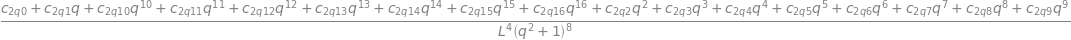

In [42]:
c_2 = c_1_2*m_d_plus
c_2_num, c_2_den = c_2.as_numer_denom()
c_2_num = collect(expand(c_2_num), [D,L,q])
c_2_num = c_2_num.xreplace({D**2: D_2, L**2: L_2, L**4: L_4})
c_2_numnum, c_2_numden = c_2_num.as_numer_denom()
c_2_numnum = collect(expand(c_2_numnum),q) # degree 16

# Assemble the q coefficients
(c_2_q0,
c_2_q1,
c_2_q2,
c_2_q3,
c_2_q4,
c_2_q5,
c_2_q6,
c_2_q7,
c_2_q8,
c_2_q9,
c_2_q10,
c_2_q11,
c_2_q12,
c_2_q13,
c_2_q14,
c_2_q15,
c_2_q16) = symbols(
    "c_2_q0, c_2_q1, c_2_q2, c_2_q3, c_2_q4, c_2_q5, c_2_q6, c_2_q7, c_2_q8, c_2_q9, c_2_q10, c_2_q11, c_2_q12, c_2_q13, c_2_q14, c_2_q15, c_2_q16")
c_2_q0t = c_2_numnum.coeff(q,0)
c_2_q1t = c_2_numnum.coeff(q,1)
c_2_q2t = c_2_numnum.coeff(q,2)
c_2_q3t = c_2_numnum.coeff(q,3)
c_2_q4t = c_2_numnum.coeff(q,4)
c_2_q5t = c_2_numnum.coeff(q,5)
c_2_q6t = c_2_numnum.coeff(q,6)
c_2_q7t = c_2_numnum.coeff(q,7)
c_2_q8t = c_2_numnum.coeff(q,8)
c_2_q9t = c_2_numnum.coeff(q,9)
c_2_q10t = c_2_numnum.coeff(q,10)
c_2_q11t = c_2_numnum.coeff(q,11)
c_2_q12t = c_2_numnum.coeff(q,12)
c_2_q13t = c_2_numnum.coeff(q,13)
c_2_q14t = c_2_numnum.coeff(q,14)
c_2_q15t = c_2_numnum.coeff(q,15)
c_2_q16t = c_2_numnum.coeff(q,16)
subs = dict(zip([c_2_q0t, c_2_q1t, c_2_q2t, c_2_q3t, c_2_q4t, c_2_q5t, c_2_q6t, c_2_q7t, c_2_q8t, c_2_q9t, c_2_q10t, c_2_q11t, c_2_q12t, c_2_q13t, c_2_q14t, c_2_q15t, c_2_q16t],
                [c_2_q0, c_2_q1, c_2_q2, c_2_q3, c_2_q4, c_2_q5, c_2_q6, c_2_q7, c_2_q8, c_2_q9, c_2_q10, c_2_q11, c_2_q12, c_2_q13, c_2_q14, c_2_q15, c_2_q16]))
c_2_numnum = c_2_numnum.subs(subs)

c_2_num = c_2_numnum/c_2_numden
# c_2_num = collect(expand(c_2_num), q)

c_2 = c_2_num/c_2_den

c_2
# c_2_num
# c_2_numnum
# c_2_numden

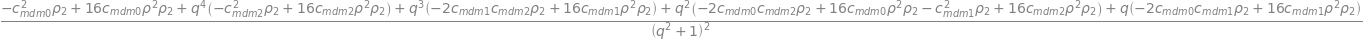

In [60]:
c_3 = 16*rho**2 - m_d_minus
rho_2 = symbols("rho_2")
c_4 = rho_2*c_3*m_d_minus
c_4_num, c_4_den = c_4.as_numer_denom()
c_4_num = collect(expand(c_4_num), q)
c_4 = c_4_num/c_4_den

c_3
c_4

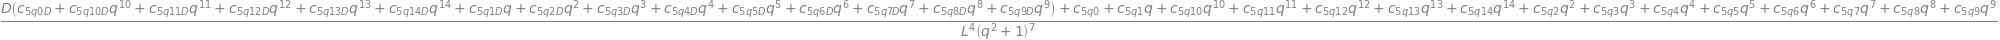

In [67]:
c_5 = v_tx**2*m_plus_x**2 + v_ty**2*m_plus_y**2
c_5_num, c_5_den = c_5.as_numer_denom()
c_5_num = collect(expand(c_5_num), [D,L,q])
c_5_num = c_5_num.xreplace({D**2: D_2, L**2: L_2, L**4: L_4})
c_5_num_num, c_5_num_den = c_5_num.as_numer_denom()
c_5_num_num = collect(expand(c_5_num_num), [D,q]) # no D: degree 14. D: degree 14.

# Combine the q coefficients
(c_5_q0,
c_5_q1,
c_5_q2,
c_5_q3,
c_5_q4,
c_5_q5,
c_5_q6,
c_5_q7,
c_5_q8,
c_5_q9,
c_5_q10,
c_5_q11,
c_5_q12,
c_5_q13,
c_5_q14) = symbols(
    "c_5_q0, c_5_q1, c_5_q2, c_5_q3, c_5_q4, c_5_q5, c_5_q6, c_5_q7, c_5_q8, c_5_q9, c_5_q10, c_5_q11, c_5_q12, c_5_q13, c_5_q14")
c_5_q0t = c_5_num_num.coeff(q,0)
c_5_q1t = c_5_num_num.coeff(q,1)
c_5_q2t = c_5_num_num.coeff(q,2)
c_5_q3t = c_5_num_num.coeff(q,3)
c_5_q4t = c_5_num_num.coeff(q,4)
c_5_q5t = c_5_num_num.coeff(q,5)
c_5_q6t = c_5_num_num.coeff(q,6)
c_5_q7t = c_5_num_num.coeff(q,7)
c_5_q8t = c_5_num_num.coeff(q,8)
c_5_q9t = c_5_num_num.coeff(q,9)
c_5_q10t = c_5_num_num.coeff(q,10)
c_5_q11t = c_5_num_num.coeff(q,11)
c_5_q12t = c_5_num_num.coeff(q,12)
c_5_q13t = c_5_num_num.coeff(q,13)
c_5_q14t = c_5_num_num.coeff(q,14)
subs = dict(zip([c_5_q0t, c_5_q1t, c_5_q2t, c_5_q3t, c_5_q4t, c_5_q5t, c_5_q6t, c_5_q7t, c_5_q8t, c_5_q9t, c_5_q10t, c_5_q11t, c_5_q12t, c_5_q13t, c_5_q14t],
                [c_5_q0, c_5_q1, c_5_q2, c_5_q3, c_5_q4, c_5_q5, c_5_q6, c_5_q7, c_5_q8, c_5_q9, c_5_q10, c_5_q11, c_5_q12, c_5_q13, c_5_q14]))
c_5_num_num = c_5_num_num.subs(subs)

# Combine the D coefficients
D_term_c5 = collect(c_5_num_num.coeff(D,1),q)
(c_5_q0D,
c_5_q1D,
c_5_q2D,
c_5_q3D,
c_5_q4D,
c_5_q5D,
c_5_q6D,
c_5_q7D,
c_5_q8D,
c_5_q9D,
c_5_q10D,
c_5_q11D,
c_5_q12D,
c_5_q13D,
c_5_q14D) = symbols(
    "c_5_q0D, c_5_q1D, c_5_q2D, c_5_q3D, c_5_q4D, c_5_q5D, c_5_q6D, c_5_q7D, c_5_q8D, c_5_q9D, c_5_q10D, c_5_q11D, c_5_q12D, c_5_q13D, c_5_q14D")
c_5_q0Dt = D_term_c5.coeff(q,0)
c_5_q1Dt = D_term_c5.coeff(q,1)
c_5_q2Dt = D_term_c5.coeff(q,2)
c_5_q3Dt = D_term_c5.coeff(q,3)
c_5_q4Dt = D_term_c5.coeff(q,4)
c_5_q5Dt = D_term_c5.coeff(q,5)
c_5_q6Dt = D_term_c5.coeff(q,6)
c_5_q7Dt = D_term_c5.coeff(q,7)
c_5_q8Dt = D_term_c5.coeff(q,8)
c_5_q9Dt = D_term_c5.coeff(q,9)
c_5_q10Dt = D_term_c5.coeff(q,10)
c_5_q11Dt = D_term_c5.coeff(q,11)
c_5_q12Dt = D_term_c5.coeff(q,12)
c_5_q13Dt = D_term_c5.coeff(q,13)
c_5_q14Dt = D_term_c5.coeff(q,14)
subs = dict(zip([c_5_q0Dt, c_5_q1Dt, c_5_q2Dt, c_5_q3Dt, c_5_q4Dt, c_5_q5Dt, c_5_q6Dt, c_5_q7Dt, c_5_q8Dt, c_5_q9Dt, c_5_q10Dt, c_5_q11Dt, c_5_q12Dt, c_5_q13Dt, c_5_q14Dt],
                [c_5_q0D, c_5_q1D, c_5_q2D, c_5_q3D, c_5_q4D, c_5_q5D, c_5_q6D, c_5_q7D, c_5_q8D, c_5_q9D, c_5_q10D, c_5_q11D, c_5_q12D, c_5_q13D, c_5_q14D]))
D_term_c5 = D_term_c5.subs(subs)

c_5_num = (c_5_num_num - D*c_5_num_num.coeff(D,1) + D*D_term_c5)/c_5_num_den

c_5 = c_5_num/c_5_den

c_5
# c_5_num
# c_5_num_den
# c_5_num_num
# D_term_c5

In [68]:
c_6 = 2*v_tx*m_plus_x*v_ty*m_plus_y


In [2]:
######### WHERE I'M AT #########

In [ ]:
### Manage c_st1

c_st1 = 2*c_s1*c_s2*m_d_plus
c_st1_num, c_st1_denom = c_st1.as_numer_denom()
c_st1_num = collect(expand(c_st1_num), [L,D,q])

# Replace D**2, L**2 and L**4 with their respective values
c_st1_num = c_st1_num.xreplace({D**2: D_2, L**2: L_2, L**4: L_4})
c_st1_num = factor(c_st1_num)
c_st1_num_num, c_st1_num_denom = c_st1_num.as_numer_denom()
c_st1_num_num = collect(expand(c_st1_num_num), q)

# Assemble the coefficients of the qs
c_st1_q0, c_st1_q1, c_st1_q2, c_st1_q3, c_st1_q4, c_st1_q5, c_st1_q6, c_st1_q7, c_st1_q8, c_st1_q9, c_st1_q10 = symbols(
    "c_st1_q0, c_st1_q1, c_st1_q2, c_st1_q3, c_st1_q4, c_st1_q5, c_st1_q6, c_st1_q7, c_st1_q8, c_st1_q9, c_st1_q10")
c_st1_q0t = c_st1_num_num.coeff(q,0)
c_st1_q1t = c_st1_num_num.coeff(q,1)
c_st1_q2t = c_st1_num_num.coeff(q,2)
c_st1_q3t = c_st1_num_num.coeff(q,3)
c_st1_q4t = c_st1_num_num.coeff(q,4)
c_st1_q5t = c_st1_num_num.coeff(q,5)
c_st1_q6t = c_st1_num_num.coeff(q,6)
c_st1_q7t = c_st1_num_num.coeff(q,7)
c_st1_q8t = c_st1_num_num.coeff(q,8)
c_st1_q9t = c_st1_num_num.coeff(q,9)
c_st1_q10t = c_st1_num_num.coeff(q,10)
subs = dict(zip([c_st1_q0t, c_st1_q1t, c_st1_q2t, c_st1_q3t, c_st1_q4t, c_st1_q5t, c_st1_q6t, c_st1_q7t, c_st1_q8t, c_st1_q9t, c_st1_q10t],
                [c_st1_q0, c_st1_q1, c_st1_q2, c_st1_q3, c_st1_q4, c_st1_q5, c_st1_q6, c_st1_q7, c_st1_q8, c_st1_q9, c_st1_q10]))
c_st1_num_num = c_st1_num_num.subs(subs)
c_st1_num = c_st1_num_num/c_st1_denom

# Get c_st1 back to its full form
c_st1 = c_st1_num/c_st1_denom

# c_st1
# c_st1_num
# c_st1_num.coeff(L,2)
# c_st1_q1

# c_st1_num_num
# c_st1_num_denom

# print(c_st1_q0t)
# print(c_st1_q1t)
# print(c_st1_q2t)
# print(c_st1_q3t)
# print(c_st1_q4t)
# print(c_st1_q5t)
# print(c_st1_q6t)
# print(c_st1_q7t)
# print(c_st1_q8t)
# print(c_st1_q9t)
# print(c_st1_q10t)

In [ ]:
################ Square up that term!#################
c_st1_2 = c_st1**2
c_st1_2_num, c_st1_2_denom = c_st1_2.as_numer_denom()
c_st1_2_num = collect(expand(c_st1_2_num), [L,D,q])
# c_st1_2_num = collect(factor(expand(c_st1_2_num)), [L,D,q])


# Bring the term back together
c_st1_2 = c_st1_2_num/c_st1_2_denom # order 20

# c_st1_2_num
# c_st1_2

In [ ]:
### Multiply c_st1**2 with c_st2 to get c_stL

c_st2 = collect(factor(m_d_minus - 4*rho), q)
c_stL = c_st1_2*c_st2
c_stL_num, c_stL_denom = c_stL.as_numer_denom()
c_stL_num = collect(expand(c_stL_num), q) # order 22

# Assemble the terms for the qs
(c_stL_q0,
c_stL_q1,
c_stL_q2,
c_stL_q3,
c_stL_q4,
c_stL_q5,
c_stL_q6,
c_stL_q7,
c_stL_q8,
c_stL_q9,
c_stL_q10,
c_stL_q11,
c_stL_q12,
c_stL_q13,
c_stL_q14,
c_stL_q15,
c_stL_q16,
c_stL_q17,
c_stL_q18,
c_stL_q19,
c_stL_q20,
c_stL_q21,
c_stL_q22) = symbols(
    "c_stL_q0, c_stL_q1, c_stL_q2, c_stL_q3, c_stL_q4, c_stL_q5, c_stL_q6, c_stL_q7, c_stL_q8, c_stL_q9, c_stL_q10, c_stL_q11, c_stL_q12, c_stL_q13, c_stL_q14, c_stL_q15, c_stL_q16, c_stL_q17, c_stL_q18, c_stL_q19, c_stL_q20, c_stL_q21, c_stL_q22")
c_stL_q0t = c_stL_num.coeff(q,0)
c_stL_q1t = c_stL_num.coeff(q,1)
c_stL_q2t = c_stL_num.coeff(q,2)
c_stL_q3t = c_stL_num.coeff(q,3)
c_stL_q4t = c_stL_num.coeff(q,4)
c_stL_q5t = c_stL_num.coeff(q,5)
c_stL_q6t = c_stL_num.coeff(q,6)
c_stL_q7t = c_stL_num.coeff(q,7)
c_stL_q8t = c_stL_num.coeff(q,8)
c_stL_q9t = c_stL_num.coeff(q,9)
c_stL_q10t = c_stL_num.coeff(q,10)
c_stL_q11t = c_stL_num.coeff(q,11)
c_stL_q12t = c_stL_num.coeff(q,12)
c_stL_q13t = c_stL_num.coeff(q,13)
c_stL_q14t = c_stL_num.coeff(q,14)
c_stL_q15t = c_stL_num.coeff(q,15)
c_stL_q16t = c_stL_num.coeff(q,16)
c_stL_q17t = c_stL_num.coeff(q,17)
c_stL_q18t = c_stL_num.coeff(q,18)
c_stL_q19t = c_stL_num.coeff(q,19)
c_stL_q20t = c_stL_num.coeff(q,20)
c_stL_q21t = c_stL_num.coeff(q,21)
c_stL_q22t = c_stL_num.coeff(q,22)
subs = dict(zip([c_stL_q0t, c_stL_q1t, c_stL_q2t, c_stL_q3t, c_stL_q4t, c_stL_q5t, c_stL_q6t, c_stL_q7t, c_stL_q8t, c_stL_q9t, c_stL_q10t, c_stL_q11t, c_stL_q12t, c_stL_q13t, c_stL_q14t, c_stL_q15t, c_stL_q16t, c_stL_q17t, c_stL_q18t, c_stL_q19t, c_stL_q20t, c_stL_q21t, c_stL_q22t],
                [c_stL_q0, c_stL_q1, c_stL_q2, c_stL_q3, c_stL_q4, c_stL_q5, c_stL_q6, c_stL_q7, c_stL_q8, c_stL_q9, c_stL_q10, c_stL_q11, c_stL_q12, c_stL_q13, c_stL_q14, c_stL_q15, c_stL_q16, c_stL_q17, c_stL_q18, c_stL_q19, c_stL_q20, c_stL_q21, c_stL_q22]))
c_stL_num = c_stL_num.subs(subs)

c_stL = c_stL_num/c_stL_denom

# c_st2
c_stL
# c_stL_num

# print(c_stL_q0t)
# print(c_stL_q1t)
# print(c_stL_q2t)
# print(c_stL_q3t)
# print(c_stL_q4t)
# print(c_stL_q5t)
# print(c_stL_q6t)
# print(c_stL_q7t)
# print(c_stL_q8t)
# print(c_stL_q9t)
# print(c_stL_q10t)
# print(c_stL_q11t)
# print(c_stL_q12t)
# print(c_stL_q13t)
# print(c_stL_q14t)
# print(c_stL_q15t)
# print(c_stL_q16t)
# print(c_stL_q17t)
# print(c_stL_q18t)
# print(c_stL_q19t)
# print(c_stL_q20t)
# print(c_stL_q21t)
# print(c_stL_q22t)

In [ ]:
### Square c_s1

c_s1 = v_tx*m_minus_x + v_ty*m_minus_y
c_s1 = collect(factor(expand(c_s1)), q)

c_s1_2 = c_s1**2
c_s1_2_num, c_s1_2_denom = c_s1_2.as_numer_denom()
c_s1_2_num = collect(expand(c_s1_2_num), q)

c_s1_2_q0, c_s1_2_q1, c_s1_2_q2 = symbols(
    "c_s1_2_q0, c_s1_2_q1, c_s1_2_q2")
c_s1_2_q0t = c_s1_2_num.coeff(q,0)
c_s1_2_q1t = c_s1_2_num.coeff(q,1)
c_s1_2_q2t = c_s1_2_num.coeff(q,2)
subs = dict(zip([c_s1_2_q1t, c_s1_2_q2t, c_s1_2_q0t],
                [c_s1_2_q1, c_s1_2_q2, c_s1_2_q0]))
c_s1_2_num = c_s1_2_num.subs(subs) # order 4, but terms 3 and 4 are the same as -1 and 0.

c_s1_2 = c_s1_2_num/c_s1_2_denom

# c_s1
c_s1_2
# c_s1_2_num
# c_s1_2_denom

# print(c_s1_2_q0t)
# print(c_s1_2_q1t)
# print(c_s1_2_q2t)

In [ ]:
### Manage c_st3

c_st3 = c_s1_2*c_st2*m_d_plus
c_st3_num, c_st3_denom = c_st3.as_numer_denom()

# Replace D**2, L**2 and L**4 with their respective values
c_st3_num = c_st3_num.xreplace({D**2: D_2, L**2: L_2, L**4: L_4})
c_st3_num = factor(c_st3_num)
c_st3_num_num, c_st3_num_denom = c_st3_num.as_numer_denom()
c_st3_num_num = collect(expand(c_st3_num_num), q) # looks like order 12

# Assemble the coefficients of the qs
c_st3_q0, c_st3_q1, c_st3_q2, c_st3_q3, c_st3_q4, c_st3_q5, c_st3_q6, c_st3_q7, c_st3_q8, c_st3_q9, c_st3_q10, c_st3_q11, c_st3_q12 = symbols(
    "c_st3_q0, c_st3_q1, c_st3_q2, c_st3_q3, c_st3_q4, c_st3_q5, c_st3_q6, c_st3_q7, c_st3_q8, c_st3_q9, c_st3_q10, c_st3_q11, c_st3_q12")
c_st3_q0t = c_st3_num_num.coeff(q,0)
c_st3_q1t = c_st3_num_num.coeff(q,1)
c_st3_q2t = c_st3_num_num.coeff(q,2)
c_st3_q3t = c_st3_num_num.coeff(q,3)
c_st3_q4t = c_st3_num_num.coeff(q,4)
c_st3_q5t = c_st3_num_num.coeff(q,5)
c_st3_q6t = c_st3_num_num.coeff(q,6)
c_st3_q7t = c_st3_num_num.coeff(q,7)
c_st3_q8t = c_st3_num_num.coeff(q,8)
c_st3_q9t = c_st3_num_num.coeff(q,9)
c_st3_q10t = c_st3_num_num.coeff(q,10)
c_st3_q11t = c_st3_num_num.coeff(q,11)
c_st3_q12t = c_st3_num_num.coeff(q,12)
subs = dict(zip([c_st3_q0t, c_st3_q1t, c_st3_q2t, c_st3_q3t, c_st3_q4t, c_st3_q5t, c_st3_q6t, c_st3_q7t, c_st3_q8t, c_st3_q9t, c_st3_q10t, c_st3_q11t, c_st3_q12t],
                [c_st3_q0, c_st3_q1, c_st3_q2, c_st3_q3, c_st3_q4, c_st3_q5, c_st3_q6, c_st3_q7, c_st3_q8, c_st3_q9, c_st3_q10, c_st3_q11, c_st3_q12]))
c_st3_num_num = c_st3_num_num.subs(subs)
c_st3_num = c_st3_num_num/c_st3_num_denom

c_st3 = c_st3_num/c_st3_denom

# c_st2
c_st3
# c_st3_num

# print(c_st3_q0t)
# print(c_st3_q1t)
# print(c_st3_q2t)
# print(c_st3_q3t)
# print(c_st3_q4t)
# print(c_st3_q5t)
# print(c_st3_q6t)
# print(c_st3_q7t)
# print(c_st3_q8t)
# print(c_st3_q9t)
# print(c_st3_q10t)
# print(c_st3_q11t)
# print(c_st3_q12t)

In [ ]:
### Square c_s2

c_s2 = v_tx*2*rho*m_minus_y - v_ty*2*rho*m_minus_x
c_s2 = collect(factor(expand(c_s2)), q)

c_s2_2 = c_s2**2
c_s2_2_num, c_s2_2_denom = c_s2_2.as_numer_denom()
c_s2_2_num = collect(expand(c_s2_2_num), q)
c_s2_2_q0, c_s2_2_q1, c_s2_2_q2, c_s2_2_q3, c_s2_2_q4 = symbols(
    "c_s2_2_q0, c_s2_2_q1, c_s2_2_q2, c_s2_2_q3, c_s2_2_q4")
c_s2_2_q0t = c_s2_2_num.coeff(q,0)
c_s2_2_q1t = c_s2_2_num.coeff(q,1)
c_s2_2_q2t = c_s2_2_num.coeff(q,2)
c_s2_2_q3t = c_s2_2_num.coeff(q,3)
c_s2_2_q4t = c_s2_2_num.coeff(q,4)
subs = dict(zip([c_s2_2_q0t, c_s2_2_q1t, c_s2_2_q2t, c_s2_2_q3t, c_s2_2_q4t],
                [c_s2_2_q0, c_s2_2_q1, c_s2_2_q2, c_s2_2_q3, c_s2_2_q4]))
c_s2_2_num = c_s2_2_num.subs(subs) # order 4, but terms 3 and 4 are the same as -1 and 0.

c_s2_2 = c_s2_2_num/c_s2_2_denom

# c_s2_2_num
c_s2_2

# print(c_s2_2_q0t)
# print(c_s2_2_q1t)
# print(c_s2_2_q2t)
# print(c_s2_2_q3t)
# print(c_s2_2_q4t)

In [ ]:
### Manage c_st4

c_st4 = c_s2_2*m_d_plus
c_st4_num, c_st4_denom = c_st4.as_numer_denom()

# Replace D**2, L**2 and L**4 with their respective values
c_st4_num = c_st4_num.xreplace({D**2: D_2, L**2: L_2, L**4: L_4})
c_st4_num = factor(c_st4_num)
c_st4_num_num, c_st4_num_denom = c_st4_num.as_numer_denom()
c_st4_num_num = collect(expand(c_st4_num_num), q) # looks like order 12

# # Assemble the coefficients of the qs
c_st4_q0, c_st4_q1, c_st4_q2, c_st4_q3, c_st4_q4, c_st4_q5, c_st4_q6, c_st4_q7, c_st4_q8, c_st4_q9, c_st4_q10 = symbols(
    "c_st4_q0, c_st4_q1, c_st4_q2, c_st4_q3, c_st4_q4, c_st4_q5, c_st4_q6, c_st4_q7, c_st4_q8, c_st4_q9, c_st4_q10")
c_st4_q0t = c_st4_num_num.coeff(q,0)
c_st4_q1t = c_st4_num_num.coeff(q,1)
c_st4_q2t = c_st4_num_num.coeff(q,2)
c_st4_q3t = c_st4_num_num.coeff(q,3)
c_st4_q4t = c_st4_num_num.coeff(q,4)
c_st4_q5t = c_st4_num_num.coeff(q,5)
c_st4_q6t = c_st4_num_num.coeff(q,6)
c_st4_q7t = c_st4_num_num.coeff(q,7)
c_st4_q8t = c_st4_num_num.coeff(q,8)
c_st4_q9t = c_st4_num_num.coeff(q,9)
c_st4_q10t = c_st4_num_num.coeff(q,10)
subs = dict(zip([c_st4_q0t, c_st4_q1t, c_st4_q2t, c_st4_q3t, c_st4_q4t, c_st4_q5t, c_st4_q6t, c_st4_q7t, c_st4_q8t, c_st4_q9t, c_st4_q10t],
                [c_st4_q0, c_st4_q1, c_st4_q2, c_st4_q3, c_st4_q4, c_st4_q5, c_st4_q6, c_st4_q7, c_st4_q8, c_st4_q9, c_st4_q10]))
c_st4_num_num = c_st4_num_num.subs(subs)
c_st4_num = c_st4_num_num/c_st4_num_denom

c_st4 = c_st4_num/c_st4_denom

c_st4
# m_d_plus

# print(c_st4_q0t)
# print(c_st4_q1t)
# print(c_st4_q2t)
# print(c_st4_q3t)
# print(c_st4_q4t)
# print(c_st4_q5t)
# print(c_st4_q6t)
# print(c_st4_q7t)
# print(c_st4_q8t)
# print(c_st4_q9t)
# print(c_st4_q10t)

In [ ]:
### Manage c_s3

c_s3 = v_tx*m_plus_x*m_d_minus + v_ty*m_plus_y*m_d_minus # Contains D not squared
c_s3 = collect(factor(expand(c_s3)), [L,D,q])

# Replace L**2 by its respective value
c_s3_num, c_s3_denom = c_s3.as_numer_denom()
c_s3_num = c_s3_num.xreplace({L**2: L_2})
c_s3_num = factor(c_s3_num)
c_s3_num_num, c_s3_num_denom = c_s3_num.as_numer_denom()
c_s3_num_num = expand(c_s3_num_num)
c_s3_num_num = collect(c_s3_num_num, [D,q])

# Assemble sub-terms NOT multiplied by D
c_s3_q0, c_s3_q1, c_s3_q2, c_s3_q3, c_s3_q4, c_s3_q5, c_s3_q6 = symbols(
    "c_s3_q0, c_s3_q1, c_s3_q2, c_s3_q3, c_s3_q4, c_s3_q5, c_s3_q6")
c_s3_q0t = c_s3_num_num.coeff(D,0).coeff(q,0)
c_s3_q1t = c_s3_num_num.coeff(D,0).coeff(q,1)
c_s3_q2t = c_s3_num_num.coeff(D,0).coeff(q,2)
c_s3_q3t = c_s3_num_num.coeff(q,3)
c_s3_q4t = c_s3_num_num.coeff(q,4)
c_s3_q5t = c_s3_num_num.coeff(q,5)
c_s3_q6t = c_s3_num_num.coeff(q,6)
subs = dict(zip([c_s3_q0t, c_s3_q1t, c_s3_q2t, c_s3_q3t, c_s3_q4t, c_s3_q5t, c_s3_q6t],
                [c_s3_q0, c_s3_q1, c_s3_q2, c_s3_q3, c_s3_q4, c_s3_q5, c_s3_q6]))
c_s3_num_num = c_s3_num_num.subs(subs)

# Assemble sub-terms multiplied by D
D_term = c_s3_num_num.coeff(D,1)
D_term = collect(D_term, q)
c_s3_q0D, c_s3_q1D, c_s3_q2D, c_s3_q3D, c_s3_q4D, c_s3_q5D, c_s3_q6D = symbols(
    "c_s3_q0D, c_s3_q1D, c_s3_q2D, c_s3_q3D, c_s3_q4D, c_s3_q5D, c_s3_q6D")
c_s3_q0Dt = c_s3_num_num.coeff(D,1).coeff(q,0)
c_s3_q1Dt = c_s3_num_num.coeff(D,1).coeff(q,1)
c_s3_q2Dt = c_s3_num_num.coeff(D,1).coeff(q,2)
c_s3_q3Dt = c_s3_num_num.coeff(D,1).coeff(q,3)
c_s3_q4Dt = c_s3_num_num.coeff(D,1).coeff(q,4)
c_s3_q5Dt = c_s3_num_num.coeff(D,1).coeff(q,5)
c_s3_q6Dt = c_s3_num_num.coeff(D,1).coeff(q,6)
subs = dict(zip([c_s3_q0Dt, c_s3_q1Dt, c_s3_q2Dt, c_s3_q3Dt, c_s3_q4Dt, c_s3_q5Dt, c_s3_q6Dt],
                [c_s3_q0D, c_s3_q1D, c_s3_q2D, c_s3_q3D, c_s3_q4D, c_s3_q5D, c_s3_q6D]))
D_term = D_term.subs(subs)

# Replace the old term in D by the new term with assembled coefficients
c_s3_num = (c_s3_num_num - D*c_s3_num_num.coeff(D,1) + D*D_term)/c_s3_num_denom
c_s3 = c_s3_num/c_s3_denom

# c_s3
# c_s3_num
# c_s3_num_num
# c_s3_denom
# L_2
# c_s3_q1t
# c_s3_q6Dt
# D_term

# print(c_s3_q0Dt)
# print(c_s3_q1Dt)
# print(c_s3_q2Dt)
# print(c_s3_q3Dt)
# print(c_s3_q4Dt)
# print(c_s3_q5Dt)
# print(c_s3_q6Dt)

# print(c_s3_q0t)
# print(c_s3_q1t)
# print(c_s3_q2t)
# print(c_s3_q3t)
# print(c_s3_q4t)
# print(c_s3_q5t)
# print(c_s3_q6t)

In [ ]:
### Square c_s3

c_s3_2 = c_s3**2
c_s3_2_num, c_s3_2_denom = c_s3_2.as_numer_denom()
c_s3_2_num = collect(expand(c_s3_2_num), [D,q])

# Replace D**2 by its value
c_s3_2_num = c_s3_2_num.xreplace({D**2: D_2})
# c_s3_2_num = factor(c_s3_2_num)
c_s3_2_num_num, c_s3_2_num_denom = c_s3_2_num.as_numer_denom()
c_s3_2_num_num = expand(c_s3_2_num_num)
c_s3_2_num_num = collect(c_s3_2_num_num, [D,q])

# Assemble sub-terms NOT multiplied by D
c_s3_2_q0, c_s3_2_q1, c_s3_2_q2, c_s3_2_q3, c_s3_2_q4, c_s3_2_q5, c_s3_2_q6, c_s3_2_q7, c_s3_2_q8, c_s3_2_q9, c_s3_2_q10, c_s3_2_q11, c_s3_2_q12, c_s3_2_q13, c_s3_2_q14 = symbols(
    "c_s3_2_q0, c_s3_2_q1, c_s3_2_q2, c_s3_2_q3, c_s3_2_q4, c_s3_2_q5, c_s3_2_q6, c_s3_2_q7, c_s3_2_q8, c_s3_2_q9, c_s3_2_q10, c_s3_2_q11, c_s3_2_q12, c_s3_2_q13, c_s3_2_q14")
c_s3_2_q0t = c_s3_2_num_num.coeff(q,0)
c_s3_2_q1t = c_s3_2_num_num.coeff(q,1)
c_s3_2_q2t = c_s3_2_num_num.coeff(q,2)
c_s3_2_q3t = c_s3_2_num_num.coeff(q,3)
c_s3_2_q4t = c_s3_2_num_num.coeff(q,4)
c_s3_2_q5t = c_s3_2_num_num.coeff(q,5)
c_s3_2_q6t = c_s3_2_num_num.coeff(q,6)
c_s3_2_q7t = c_s3_2_num_num.coeff(q,7)
c_s3_2_q8t = c_s3_2_num_num.coeff(q,8)
c_s3_2_q9t = c_s3_2_num_num.coeff(q,9)
c_s3_2_q10t = c_s3_2_num_num.coeff(q,10)
c_s3_2_q11t = c_s3_2_num_num.coeff(q,11)
c_s3_2_q12t = c_s3_2_num_num.coeff(q,12)
c_s3_2_q13t = c_s3_2_num_num.coeff(q,13)
c_s3_2_q14t = c_s3_2_num_num.coeff(q,14)
subs = dict(zip([c_s3_2_q0t, c_s3_2_q1t, c_s3_2_q2t, c_s3_2_q3t, c_s3_2_q4t, c_s3_2_q5t, c_s3_2_q6t, c_s3_2_q7t, c_s3_2_q8t, c_s3_2_q9t, c_s3_2_q10t, c_s3_2_q11t, c_s3_2_q12t, c_s3_2_q13t, c_s3_2_q14t],
                [c_s3_2_q0, c_s3_2_q1, c_s3_2_q2, c_s3_2_q3, c_s3_2_q4, c_s3_2_q5, c_s3_2_q6, c_s3_2_q7, c_s3_2_q8, c_s3_2_q9, c_s3_2_q10, c_s3_2_q11, c_s3_2_q12, c_s3_2_q13, c_s3_2_q14]))
c_s3_2_num_num = c_s3_2_num_num.subs(subs)

# Assemble sub-terms multiplied by D
D_term = c_s3_2_num_num.coeff(D,1)
D_term = collect(D_term, q)
c_s3_2_q1D, c_s3_2_q2D, c_s3_2_q3D, c_s3_2_q4D, c_s3_2_q5D, c_s3_2_q6D, c_s3_2_q7D, c_s3_2_q8D, c_s3_2_q9D, c_s3_2_q10D, c_s3_2_q11D, c_s3_2_q12D, c_s3_2_q13D = symbols(
    "c_s3_2_q1D, c_s3_2_q2D, c_s3_2_q3D, c_s3_2_q4D, c_s3_2_q5D, c_s3_2_q6D, c_s3_2_q7D, c_s3_2_q8D, c_s3_2_q9D, c_s3_2_q10D, c_s3_2_q11D, c_s3_2_q12D, c_s3_2_q13D")
c_s3_2_q1Dt = c_s3_2_num_num.coeff(D,1).coeff(q,1)
c_s3_2_q2Dt = c_s3_2_num_num.coeff(D,1).coeff(q,2)
c_s3_2_q3Dt = c_s3_2_num_num.coeff(D,1).coeff(q,3)
c_s3_2_q4Dt = c_s3_2_num_num.coeff(D,1).coeff(q,4)
c_s3_2_q5Dt = c_s3_2_num_num.coeff(D,1).coeff(q,5)
c_s3_2_q6Dt = c_s3_2_num_num.coeff(D,1).coeff(q,6)
c_s3_2_q7Dt = c_s3_2_num_num.coeff(D,1).coeff(q,7)
c_s3_2_q8Dt = c_s3_2_num_num.coeff(D,1).coeff(q,8)
c_s3_2_q9Dt = c_s3_2_num_num.coeff(D,1).coeff(q,9)
c_s3_2_q10Dt = c_s3_2_num_num.coeff(D,1).coeff(q,10)
c_s3_2_q11Dt = c_s3_2_num_num.coeff(D,1).coeff(q,11)
c_s3_2_q12Dt = c_s3_2_num_num.coeff(D,1).coeff(q,12)
c_s3_2_q13Dt = c_s3_2_num_num.coeff(D,1).coeff(q,13)
subs = dict(zip([c_s3_2_q1Dt, c_s3_2_q2Dt, c_s3_2_q3Dt, c_s3_2_q4Dt, c_s3_2_q5Dt, c_s3_2_q6Dt, c_s3_2_q7Dt, c_s3_2_q8Dt, c_s3_2_q9Dt, c_s3_2_q10Dt, c_s3_2_q11Dt, c_s3_2_q12Dt, c_s3_2_q13Dt],
                [c_s3_2_q1D, c_s3_2_q2D, c_s3_2_q3D, c_s3_2_q4D, c_s3_2_q5D, c_s3_2_q6D, c_s3_2_q7D, c_s3_2_q8D, c_s3_2_q9D, c_s3_2_q10D, c_s3_2_q11D, c_s3_2_q12D, c_s3_2_q13D]))
D_term = D_term.subs(subs)

# Replace the old term in D by the new term with assembled coefficients
c_s3_2_num_num = c_s3_2_num_num - D*c_s3_2_num_num.coeff(D,1) + D*D_term

c_s3_2_num = c_s3_2_num_num/c_s3_2_num_denom
c_s3_2 = c_s3_2_num/c_s3_2_denom

# c_s3_2
# c_s3_2_num
# c_s3_2_num_num
# D_term
# c_s3_2_num_denom

# print(c_s3_2_q1Dt)
# print(c_s3_2_q2Dt)
# print(c_s3_2_q3Dt)
# print(c_s3_2_q4Dt)
# print(c_s3_2_q5Dt)
# print(c_s3_2_q6Dt)
# print(c_s3_2_q7Dt)
# print(c_s3_2_q8Dt)
# print(c_s3_2_q9Dt)
# print(c_s3_2_q10Dt)
# print(c_s3_2_q11Dt)
# print(c_s3_2_q12Dt)
# print(c_s3_2_q13Dt)

# print(c_s3_2_q0t)
# print(c_s3_2_q1t)
# print(c_s3_2_q2t)
# print(c_s3_2_q3t)
# print(c_s3_2_q4t)
# print(c_s3_2_q5t)
# print(c_s3_2_q6t)
# print(c_s3_2_q7t)
# print(c_s3_2_q8t)
# print(c_s3_2_q9t)
# print(c_s3_2_q10t)
# print(c_s3_2_q11t)
# print(c_s3_2_q12t)
# print(c_s3_2_q13t)
# print(c_s3_2_q14t)

In [ ]:
### Simplify right side of equality in eq 59 before squaring it up

c_stR = c_s3_2 - c_st3 - c_st4
c_stR = collect(factor(c_stR), [D,q])

# Assemble the terms NOT multiplied by D
c_stR_num, c_stR_denom = c_stR.as_numer_denom()

(c_stR_q0,
c_stR_q1,
c_stR_q2,
c_stR_q3,
c_stR_q4,
c_stR_q5,
c_stR_q6,
c_stR_q7,
c_stR_q8,
c_stR_q9,
c_stR_q10,
c_stR_q11,
c_stR_q12,
c_stR_q13,
c_stR_q14) = symbols("c_stR_q0, c_stR_q1, c_stR_q2, c_stR_q3, c_stR_q4, c_stR_q5, c_stR_q6, c_stR_q7, c_stR_q8, c_stR_q9, c_stR_q10, c_stR_q11, c_stR_q12, c_stR_q13, c_stR_q14")
c_stR_q0t = c_stR_num.coeff(q,0)
c_stR_q1t = c_stR_num.coeff(q,1)
c_stR_q2t = c_stR_num.coeff(q,2)
c_stR_q3t = c_stR_num.coeff(q,3)
c_stR_q4t = c_stR_num.coeff(q,4)
c_stR_q5t = c_stR_num.coeff(q,5)
c_stR_q6t = c_stR_num.coeff(q,6)
c_stR_q7t = c_stR_num.coeff(q,7)
c_stR_q8t = c_stR_num.coeff(q,8)
c_stR_q9t = c_stR_num.coeff(q,9)
c_stR_q10t = c_stR_num.coeff(q,10)
c_stR_q11t = c_stR_num.coeff(q,11)
c_stR_q12t = c_stR_num.coeff(q,12)
c_stR_q13t = c_stR_num.coeff(q,13)
c_stR_q14t = c_stR_num.coeff(q,14)
subs = dict(zip([c_stR_q0t, c_stR_q1t, c_stR_q2t, c_stR_q3t, c_stR_q4t, c_stR_q5t, c_stR_q6t, c_stR_q7t, c_stR_q8t, c_stR_q9t, c_stR_q10t, c_stR_q11t, c_stR_q12t, c_stR_q13t, c_stR_q14t],
                [c_stR_q0, c_stR_q1, c_stR_q2, c_stR_q3, c_stR_q4, c_stR_q5, c_stR_q6, c_stR_q7, c_stR_q8, c_stR_q9, c_stR_q10, c_stR_q11, c_stR_q12, c_stR_q13, c_stR_q14]))
c_stR_num = c_stR_num.subs(subs)
c_stR = c_stR_num/c_stR_denom

c_stR
# c_stR_num
# c_stR_2_denom

# print(c_stR_q0t)
# print(c_stR_q1t)
# print(c_stR_q2t)
# print(c_stR_q3t)
# print(c_stR_q4t)
# print(c_stR_q5t)
# print(c_stR_q6t)
# print(c_stR_q7t)
# print(c_stR_q8t)
# print(c_stR_q9t)
# print(c_stR_q10t)
# print(c_stR_q11t)
# print(c_stR_q12t)
# print(c_stR_q13t)
# print(c_stR_q14t)

In [ ]:
### Square the right side of the equality in eq 59

c_stR_2 = c_stR**2
c_stR_2_num, c_stR_2_denom = c_stR_2.as_numer_denom()

c_stR_2_num = collect(expand(c_stR_2_num), [D,q])
c_stR_2_num = c_stR_2_num.xreplace({D**2: D_2})
c_stR_2_num_num, c_stR_2_num_denom = c_stR_2_num.as_numer_denom()
c_stR_2_num_num = collect(expand(c_stR_2_num_num), [D,q])

# Assemble the terms NOT multiplied by D
(c_stR_2_q0,
c_stR_2_q1,
c_stR_2_q2,
c_stR_2_q3,
c_stR_2_q4,
c_stR_2_q5,
c_stR_2_q6,
c_stR_2_q7,
c_stR_2_q8,
c_stR_2_q9,
c_stR_2_q10,
c_stR_2_q11,
c_stR_2_q12,
c_stR_2_q13,
c_stR_2_q14,
c_stR_2_q15,
c_stR_2_q16,
c_stR_2_q17,
c_stR_2_q18,
c_stR_2_q19,
c_stR_2_q20,
c_stR_2_q21,
c_stR_2_q22,
c_stR_2_q23,
c_stR_2_q24,
c_stR_2_q25,
c_stR_2_q26,
c_stR_2_q27,
c_stR_2_q28,
c_stR_2_q29,
c_stR_2_q30) = symbols(
    "c_stR_2_q0, c_stR_2_q1, c_stR_2_q2, c_stR_2_q3, c_stR_2_q4, c_stR_2_q5, c_stR_2_q6, c_stR_2_q7, c_stR_2_q8, c_stR_2_q9, c_stR_2_q10, c_stR_2_q11, c_stR_2_q12, c_stR_2_q13, c_stR_2_q14, c_stR_2_q15, c_stR_2_q16, c_stR_2_q17, c_stR_2_q18, c_stR_2_q19, c_stR_2_q20, c_stR_2_q21, c_stR_2_q22, c_stR_2_q23, c_stR_2_q24, c_stR_2_q25, c_stR_2_q26, c_stR_2_q27, c_stR_2_q28, c_stR_2_q29, c_stR_2_q30")
c_stR_2_q0t = c_stR_2_num_num.coeff(q,0)
c_stR_2_q1t = c_stR_2_num_num.coeff(q,1)
c_stR_2_q2t = c_stR_2_num_num.coeff(q,2)
c_stR_2_q3t = c_stR_2_num_num.coeff(q,3)
c_stR_2_q4t = c_stR_2_num_num.coeff(q,4)
c_stR_2_q5t = c_stR_2_num_num.coeff(q,5)
c_stR_2_q6t = c_stR_2_num_num.coeff(q,6)
c_stR_2_q7t = c_stR_2_num_num.coeff(q,7)
c_stR_2_q8t = c_stR_2_num_num.coeff(q,8)
c_stR_2_q9t = c_stR_2_num_num.coeff(q,9)
c_stR_2_q10t = c_stR_2_num_num.coeff(q,10)
c_stR_2_q11t = c_stR_2_num_num.coeff(q,11)
c_stR_2_q12t = c_stR_2_num_num.coeff(q,12)
c_stR_2_q13t = c_stR_2_num_num.coeff(q,13)
c_stR_2_q14t = c_stR_2_num_num.coeff(q,14)
c_stR_2_q15t = c_stR_2_num_num.coeff(q,15)
c_stR_2_q16t = c_stR_2_num_num.coeff(q,16)
c_stR_2_q17t = c_stR_2_num_num.coeff(q,17)
c_stR_2_q18t = c_stR_2_num_num.coeff(q,18)
c_stR_2_q19t = c_stR_2_num_num.coeff(q,19)
c_stR_2_q20t = c_stR_2_num_num.coeff(q,20)
c_stR_2_q21t = c_stR_2_num_num.coeff(q,21)
c_stR_2_q22t = c_stR_2_num_num.coeff(q,22)
c_stR_2_q23t = c_stR_2_num_num.coeff(q,23)
c_stR_2_q24t = c_stR_2_num_num.coeff(q,24)
c_stR_2_q25t = c_stR_2_num_num.coeff(q,25)
c_stR_2_q26t = c_stR_2_num_num.coeff(q,26)
c_stR_2_q27t = c_stR_2_num_num.coeff(q,27)
c_stR_2_q28t = c_stR_2_num_num.coeff(q,28)
c_stR_2_q29t = c_stR_2_num_num.coeff(q,29)
c_stR_2_q30t = c_stR_2_num_num.coeff(q,30)
subs = dict(zip([c_stR_2_q0t, c_stR_2_q1t, c_stR_2_q2t, c_stR_2_q3t, c_stR_2_q4t, c_stR_2_q5t, c_stR_2_q6t, c_stR_2_q7t, c_stR_2_q8t, c_stR_2_q9t, c_stR_2_q10t, c_stR_2_q11t, c_stR_2_q12t, c_stR_2_q13t, c_stR_2_q14t, c_stR_2_q15t, c_stR_2_q16t, c_stR_2_q17t, c_stR_2_q18t, c_stR_2_q19t, c_stR_2_q20t, c_stR_2_q21t, c_stR_2_q22t, c_stR_2_q23t, c_stR_2_q24t, c_stR_2_q25t, c_stR_2_q26t, c_stR_2_q27t, c_stR_2_q28t, c_stR_2_q29t, c_stR_2_q30t],
                [c_stR_2_q0, c_stR_2_q1, c_stR_2_q2, c_stR_2_q3, c_stR_2_q4, c_stR_2_q5, c_stR_2_q6, c_stR_2_q7, c_stR_2_q8, c_stR_2_q9, c_stR_2_q10, c_stR_2_q11, c_stR_2_q12, c_stR_2_q13, c_stR_2_q14, c_stR_2_q15, c_stR_2_q16, c_stR_2_q17, c_stR_2_q18, c_stR_2_q19, c_stR_2_q20, c_stR_2_q21, c_stR_2_q22, c_stR_2_q23, c_stR_2_q24, c_stR_2_q25, c_stR_2_q26, c_stR_2_q27, c_stR_2_q28, c_stR_2_q29, c_stR_2_q30]))
c_stR_2_num_num = c_stR_2_num_num.subs(subs)

# Assemble the terms multiplied by D
D_term = c_stR_2_num_num.coeff(D,1)
D_term = collect(D_term, q)
(c_stR_2_q1D,
c_stR_2_q2D,
c_stR_2_q3D,
c_stR_2_q4D,
c_stR_2_q5D,
c_stR_2_q6D,
c_stR_2_q7D,
c_stR_2_q8D,
c_stR_2_q9D,
c_stR_2_q10D,
c_stR_2_q11D,
c_stR_2_q12D,
c_stR_2_q13D,
c_stR_2_q14D,
c_stR_2_q15D,
c_stR_2_q16D,
c_stR_2_q17D,
c_stR_2_q18D,
c_stR_2_q19D,
c_stR_2_q20D,
c_stR_2_q21D,
c_stR_2_q22D,
c_stR_2_q23D,
c_stR_2_q24D,
c_stR_2_q25D,
c_stR_2_q26D,
c_stR_2_q27D,
c_stR_2_q28D,
c_stR_2_q29D) = symbols(
    "c_stR_2_q1D, c_stR_2_q2D, c_stR_2_q3D, c_stR_2_q4D, c_stR_2_q5D, c_stR_2_q6D, c_stR_2_q7D, c_stR_2_q8D, c_stR_2_q9D, c_stR_2_q10D, c_stR_2_q11D, c_stR_2_q12D, c_stR_2_q13D, c_stR_2_q14D, c_stR_2_q15D, c_stR_2_q16D, c_stR_2_q17D, c_stR_2_q18D, c_stR_2_q19D, c_stR_2_q20D, c_stR_2_q21D, c_stR_2_q22D, c_stR_2_q23D, c_stR_2_q24D, c_stR_2_q25D, c_stR_2_q26D, c_stR_2_q27D, c_stR_2_q28D, c_stR_2_q29D")
c_stR_2_q1Dt = D_term.coeff(q,1)
c_stR_2_q2Dt = D_term.coeff(q,2)
c_stR_2_q3Dt = D_term.coeff(q,3)
c_stR_2_q4Dt = D_term.coeff(q,4)
c_stR_2_q5Dt = D_term.coeff(q,5)
c_stR_2_q6Dt = D_term.coeff(q,6)
c_stR_2_q7Dt = D_term.coeff(q,7)
c_stR_2_q8Dt = D_term.coeff(q,8)
c_stR_2_q9Dt = D_term.coeff(q,9)
c_stR_2_q10Dt = D_term.coeff(q,10)
c_stR_2_q11Dt = D_term.coeff(q,11)
c_stR_2_q12Dt = D_term.coeff(q,12)
c_stR_2_q13Dt = D_term.coeff(q,13)
c_stR_2_q14Dt = D_term.coeff(q,14)
c_stR_2_q15Dt = D_term.coeff(q,15)
c_stR_2_q16Dt = D_term.coeff(q,16)
c_stR_2_q17Dt = D_term.coeff(q,17)
c_stR_2_q18Dt = D_term.coeff(q,18)
c_stR_2_q19Dt = D_term.coeff(q,19)
c_stR_2_q20Dt = D_term.coeff(q,20)
c_stR_2_q21Dt = D_term.coeff(q,21)
c_stR_2_q22Dt = D_term.coeff(q,22)
c_stR_2_q23Dt = D_term.coeff(q,23)
c_stR_2_q24Dt = D_term.coeff(q,24)
c_stR_2_q25Dt = D_term.coeff(q,25)
c_stR_2_q26Dt = D_term.coeff(q,26)
c_stR_2_q27Dt = D_term.coeff(q,27)
c_stR_2_q28Dt = D_term.coeff(q,28)
c_stR_2_q29Dt = D_term.coeff(q,29)
subs = dict(zip([c_stR_2_q1Dt, c_stR_2_q2Dt, c_stR_2_q3Dt, c_stR_2_q4Dt, c_stR_2_q5Dt, c_stR_2_q6Dt, c_stR_2_q7Dt, c_stR_2_q8Dt, c_stR_2_q9Dt, c_stR_2_q10Dt, c_stR_2_q11Dt, c_stR_2_q12Dt, c_stR_2_q13Dt, c_stR_2_q14Dt, c_stR_2_q15Dt, c_stR_2_q16Dt, c_stR_2_q17Dt, c_stR_2_q18Dt, c_stR_2_q19Dt, c_stR_2_q20Dt, c_stR_2_q21Dt, c_stR_2_q22Dt, c_stR_2_q23Dt, c_stR_2_q24Dt, c_stR_2_q25Dt, c_stR_2_q26Dt, c_stR_2_q27Dt, c_stR_2_q28Dt, c_stR_2_q29Dt],
                [c_stR_2_q1D, c_stR_2_q2D, c_stR_2_q3D, c_stR_2_q4D, c_stR_2_q5D, c_stR_2_q6D, c_stR_2_q7D, c_stR_2_q8D, c_stR_2_q9D, c_stR_2_q10D, c_stR_2_q11D, c_stR_2_q12D, c_stR_2_q13D, c_stR_2_q14D, c_stR_2_q15D, c_stR_2_q16D, c_stR_2_q17D, c_stR_2_q18D, c_stR_2_q19D, c_stR_2_q20D, c_stR_2_q21D, c_stR_2_q22D, c_stR_2_q23D, c_stR_2_q24D, c_stR_2_q25D, c_stR_2_q26D, c_stR_2_q27D, c_stR_2_q28D, c_stR_2_q29D]))
D_term = D_term.subs(subs)

c_stR_2_num_num = c_stR_2_num_num - D*c_stR_2_num_num.coeff(D,1) + D*D_term

c_stR_2_num = c_stR_2_num_num/c_stR_2_num_denom

# c_stR_2_num = collect(expand(c_stR_2_num), [D,q])

c_stR_2 = c_stR_2_num/c_stR_2_denom

c_stR_2
# c_stR_2_num
# c_stR_2_num_num
# D_term

# print(c_stR_2_q1Dt)
# print(c_stR_2_q2Dt)
# print(c_stR_2_q3Dt)
# print(c_stR_2_q4Dt)
# print(c_stR_2_q5Dt)
# print(c_stR_2_q6Dt)
# print(c_stR_2_q7Dt)
# print(c_stR_2_q8Dt)
# print(c_stR_2_q9Dt)
# print(c_stR_2_q10Dt)
# print(c_stR_2_q11Dt)
# print(c_stR_2_q12Dt)
# print(c_stR_2_q13Dt)
# print(c_stR_2_q14Dt)
# print(c_stR_2_q15Dt)
# print(c_stR_2_q16Dt)
# print(c_stR_2_q17Dt)
# print(c_stR_2_q18Dt)
# print(c_stR_2_q19Dt)
# print(c_stR_2_q20Dt)
# print(c_stR_2_q21Dt)
# print(c_stR_2_q22Dt)
# print(c_stR_2_q23Dt)
# print(c_stR_2_q24Dt)
# print(c_stR_2_q25Dt)
# print(c_stR_2_q26Dt)
# print(c_stR_2_q27Dt)
# print(c_stR_2_q28Dt)
# print(c_stR_2_q29Dt)

# print(c_stR_2_q0t)
# print(c_stR_2_q1t)
# print(c_stR_2_q2t)
# print(c_stR_2_q3t)
# print(c_stR_2_q4t)
# print(c_stR_2_q5t)
# print(c_stR_2_q6t)
# print(c_stR_2_q7t)
# print(c_stR_2_q8t)
# print(c_stR_2_q9t)
# print(c_stR_2_q10t)
# print(c_stR_2_q11t)
# print(c_stR_2_q12t)
# print(c_stR_2_q13t)
# print(c_stR_2_q14t)
# print(c_stR_2_q15t)
# print(c_stR_2_q16t)
# print(c_stR_2_q17t)
# print(c_stR_2_q18t)
# print(c_stR_2_q19t)
# print(c_stR_2_q20t)
# print(c_stR_2_q21t)
# print(c_stR_2_q22t)
# print(c_stR_2_q23t)
# print(c_stR_2_q24t)
# print(c_stR_2_q25t)
# print(c_stR_2_q26t)
# print(c_stR_2_q27t)
# print(c_stR_2_q28t)
# print(c_stR_2_q29t)
# print(c_stR_2_q30t)

In [ ]:
### Manage the numerators of c_stL == c_stR_2

c_stL_num, c_stL_denom = c_stL.as_numer_denom()
c_stR_2_num, c_stR_2_denom = c_stR_2.as_numer_denom()

# c_stL_num
# print(c_stL_denom) # = L**16*(q**2+1)**13
# c_stR_2_num
# print(c_stR_2_denom) # = L**8*(q**2+1)**15

# We can cancel L**8*(q**2+1)**13 on both sides
c_stL_denom_v2 = L**8
c_stR_2_denom_v2 = (q**2+1)**2

# c_stL_denom

c_stL_v2 = c_stL_num/c_stL_denom_v2
c_stR_2_v2 = c_stR_2_num/c_stR_2_denom_v2

# c_stL
c_stR_2
# c_stL_num
# c_stR_2_num
# c_stL_denom
# c_stR_2_denom
c_stL_v2
c_stR_2_v2

In [ ]:
### Get rid of the denominators

c_stL_v2_num, c_stL_v2_denom = c_stL_v2.as_numer_denom()
c_stR_2_v2_num, c_stR_2_v2_denom = c_stR_2_v2.as_numer_denom()

# This adds things in the denominator because of L**8. We then need to multiply
# the other term by that denominator.
c_R = c_stR_2_v2_num*L_8
c_R_num, c_R_denom = c_R.as_numer_denom()
c_R = c_R_num
c_R = collect(expand(c_R), [D,q]) # order 38, only 1 term for 0 and 38.

# Assemble the terms for the qs, NOT multiplied by D
(c_R_q1,
c_R_q2,
c_R_q3,
c_R_q4,
c_R_q5,
c_R_q6,
c_R_q7,
c_R_q8,
c_R_q9,
c_R_q10,
c_R_q11,
c_R_q12,
c_R_q13,
c_R_q14,
c_R_q15,
c_R_q16,
c_R_q17,
c_R_q18,
c_R_q19,
c_R_q20,
c_R_q21,
c_R_q22,
c_R_q23,
c_R_q24,
c_R_q25,
c_R_q26,
c_R_q27,
c_R_q28,
c_R_q29,
c_R_q30,
c_R_q31,
c_R_q32,
c_R_q33,
c_R_q34,
c_R_q35,
c_R_q36,
c_R_q37) = symbols(
    "c_R_q1, c_R_q2, c_R_q3, c_R_q4, c_R_q5, c_R_q6, c_R_q7, c_R_q8, c_R_q9, c_R_q10, c_R_q11, c_R_q12, c_R_q13, c_R_q14, c_R_q15, c_R_q16, c_R_q17, c_R_q18, c_R_q19, c_R_q20, c_R_q21, c_R_q22, c_R_q23, c_R_q24, c_R_q25, c_R_q26, c_R_q27, c_R_q28, c_R_q29, c_R_q30, c_R_q31, c_R_q32, c_R_q33, c_R_q34, c_R_q35, c_R_q36, c_R_q37")
c_R_q1t = c_R.coeff(q,1)
c_R_q2t = c_R.coeff(q,2)
c_R_q3t = c_R.coeff(q,3)
c_R_q4t = c_R.coeff(q,4)
c_R_q5t = c_R.coeff(q,5)
c_R_q6t = c_R.coeff(q,6)
c_R_q7t = c_R.coeff(q,7)
c_R_q8t = c_R.coeff(q,8)
c_R_q9t = c_R.coeff(q,9)
c_R_q10t = c_R.coeff(q,10)
c_R_q11t = c_R.coeff(q,11)
c_R_q12t = c_R.coeff(q,12)
c_R_q13t = c_R.coeff(q,13)
c_R_q14t = c_R.coeff(q,14)
c_R_q15t = c_R.coeff(q,15)
c_R_q16t = c_R.coeff(q,16)
c_R_q17t = c_R.coeff(q,17)
c_R_q18t = c_R.coeff(q,18)
c_R_q19t = c_R.coeff(q,19)
c_R_q20t = c_R.coeff(q,20)
c_R_q21t = c_R.coeff(q,21)
c_R_q22t = c_R.coeff(q,22)
c_R_q23t = c_R.coeff(q,23)
c_R_q24t = c_R.coeff(q,24)
c_R_q25t = c_R.coeff(q,25)
c_R_q26t = c_R.coeff(q,26)
c_R_q27t = c_R.coeff(q,27)
c_R_q28t = c_R.coeff(q,28)
c_R_q29t = c_R.coeff(q,29)
c_R_q30t = c_R.coeff(q,30)
c_R_q31t = c_R.coeff(q,31)
c_R_q32t = c_R.coeff(q,32)
c_R_q33t = c_R.coeff(q,33)
c_R_q34t = c_R.coeff(q,34)
c_R_q35t = c_R.coeff(q,35)
c_R_q36t = c_R.coeff(q,36)
c_R_q37t = c_R.coeff(q,37)
subs = dict(zip([c_R_q1t, c_R_q2t, c_R_q3t, c_R_q4t, c_R_q5t, c_R_q6t, c_R_q7t, c_R_q8t, c_R_q9t, c_R_q10t, c_R_q11t, c_R_q12t, c_R_q13t, c_R_q14t, c_R_q15t, c_R_q16t, c_R_q17t, c_R_q18t, c_R_q19t, c_R_q20t, c_R_q21t, c_R_q22t, c_R_q23t, c_R_q24t, c_R_q25t, c_R_q26t, c_R_q27t, c_R_q28t, c_R_q29t, c_R_q30t, c_R_q31t, c_R_q32t, c_R_q33t, c_R_q34t, c_R_q35t, c_R_q36t, c_R_q37t],
                [c_R_q1, c_R_q2, c_R_q3, c_R_q4, c_R_q5, c_R_q6, c_R_q7, c_R_q8, c_R_q9, c_R_q10, c_R_q11, c_R_q12, c_R_q13, c_R_q14, c_R_q15, c_R_q16, c_R_q17, c_R_q18, c_R_q19, c_R_q20, c_R_q21, c_R_q22, c_R_q23, c_R_q24, c_R_q25, c_R_q26, c_R_q27, c_R_q28, c_R_q29, c_R_q30, c_R_q31, c_R_q32, c_R_q33, c_R_q34, c_R_q35, c_R_q36, c_R_q37]))
c_R = c_R.subs(subs)

# Assemble the terms for the qs, multiplied by D
D_term = c_R.coeff(D,1) # goes to order 38
D_term = collect(D_term, q)
(c_R_q1D,
c_R_q2D,
c_R_q3D,
c_R_q4D,
c_R_q5D,
c_R_q6D,
c_R_q7D,
c_R_q8D,
c_R_q9D,
c_R_q10D,
c_R_q11D,
c_R_q12D,
c_R_q13D,
c_R_q14D,
c_R_q15D,
c_R_q16D,
c_R_q17D,
c_R_q18D,
c_R_q19D,
c_R_q20D,
c_R_q21D,
c_R_q22D,
c_R_q23D,
c_R_q24D,
c_R_q25D,
c_R_q26D,
c_R_q27D,
c_R_q28D,
c_R_q29D,
c_R_q30D,
c_R_q31D,
c_R_q32D,
c_R_q33D,
c_R_q34D,
c_R_q35D,
c_R_q36D,
c_R_q37D) = symbols(
    "c_R_q1D, c_R_q2D, c_R_q3D, c_R_q4D, c_R_q5D, c_R_q6D, c_R_q7D, c_R_q8D, c_R_q9D, c_R_q10D, c_R_q11D, c_R_q12D, c_R_q13D, c_R_q14D, c_R_q15D, c_R_q16D, c_R_q17D, c_R_q18D, c_R_q19D, c_R_q20D, c_R_q21D, c_R_q22D, c_R_q23D, c_R_q24D, c_R_q25D, c_R_q26D, c_R_q27D, c_R_q28D, c_R_q29D, c_R_q30D, c_R_q31D, c_R_q32D, c_R_q33D, c_R_q34D, c_R_q35D, c_R_q36D, c_R_q37D")
c_R_q1Dt = D_term.coeff(q,1)
c_R_q2Dt = D_term.coeff(q,2)
c_R_q3Dt = D_term.coeff(q,3)
c_R_q4Dt = D_term.coeff(q,4)
c_R_q5Dt = D_term.coeff(q,5)
c_R_q6Dt = D_term.coeff(q,6)
c_R_q7Dt = D_term.coeff(q,7)
c_R_q8Dt = D_term.coeff(q,8)
c_R_q9Dt = D_term.coeff(q,9)
c_R_q10Dt = D_term.coeff(q,10)
c_R_q11Dt = D_term.coeff(q,11)
c_R_q12Dt = D_term.coeff(q,12)
c_R_q13Dt = D_term.coeff(q,13)
c_R_q14Dt = D_term.coeff(q,14)
c_R_q15Dt = D_term.coeff(q,15)
c_R_q16Dt = D_term.coeff(q,16)
c_R_q17Dt = D_term.coeff(q,17)
c_R_q18Dt = D_term.coeff(q,18)
c_R_q19Dt = D_term.coeff(q,19)
c_R_q20Dt = D_term.coeff(q,20)
c_R_q21Dt = D_term.coeff(q,21)
c_R_q22Dt = D_term.coeff(q,22)
c_R_q23Dt = D_term.coeff(q,23)
c_R_q24Dt = D_term.coeff(q,24)
c_R_q25Dt = D_term.coeff(q,25)
c_R_q26Dt = D_term.coeff(q,26)
c_R_q27Dt = D_term.coeff(q,27)
c_R_q28Dt = D_term.coeff(q,28)
c_R_q29Dt = D_term.coeff(q,29)
c_R_q30Dt = D_term.coeff(q,30)
c_R_q31Dt = D_term.coeff(q,31)
c_R_q32Dt = D_term.coeff(q,32)
c_R_q33Dt = D_term.coeff(q,33)
c_R_q34Dt = D_term.coeff(q,34)
c_R_q35Dt = D_term.coeff(q,35)
c_R_q36Dt = D_term.coeff(q,36)
c_R_q37Dt = D_term.coeff(q,37)
subs = dict(zip([c_R_q1Dt, c_R_q2Dt, c_R_q3Dt, c_R_q4Dt, c_R_q5Dt, c_R_q6Dt, c_R_q7Dt, c_R_q8Dt, c_R_q9Dt, c_R_q10Dt, c_R_q11Dt, c_R_q12Dt, c_R_q13Dt, c_R_q14Dt, c_R_q15Dt, c_R_q16Dt, c_R_q17Dt, c_R_q18Dt, c_R_q19Dt, c_R_q20Dt, c_R_q21Dt, c_R_q22Dt, c_R_q23Dt, c_R_q24Dt, c_R_q25Dt, c_R_q26Dt, c_R_q27Dt, c_R_q28Dt, c_R_q29Dt, c_R_q30Dt, c_R_q31Dt, c_R_q32Dt, c_R_q33Dt, c_R_q34Dt, c_R_q35Dt, c_R_q36Dt, c_R_q37Dt],
                [c_R_q1D, c_R_q2D, c_R_q3D, c_R_q4D, c_R_q5D, c_R_q6D, c_R_q7D, c_R_q8D, c_R_q9D, c_R_q10D, c_R_q11D, c_R_q12D, c_R_q13D, c_R_q14D, c_R_q15D, c_R_q16D, c_R_q17D, c_R_q18D, c_R_q19D, c_R_q20D, c_R_q21D, c_R_q22D, c_R_q23D, c_R_q24D, c_R_q25D, c_R_q26D, c_R_q27D, c_R_q28D, c_R_q29D, c_R_q30D, c_R_q31D, c_R_q32D, c_R_q33D, c_R_q34D, c_R_q35D, c_R_q36D, c_R_q37D]))
D_term = D_term.subs(subs)
c_R = c_R - D*c_R.coeff(D,1) + D*D_term


### Manage c_L
c_L = c_stL_v2_num*((q**2+1)**2)*c_R_denom
c_L = collect(expand(c_L), q) # order 34, only 1 term for 0, 1, 33, 34.

# Assemble the qs coefficients for orders 2 to 32
(c_L_q2,
c_L_q3,
c_L_q4,
c_L_q5,
c_L_q6,
c_L_q7,
c_L_q8,
c_L_q9,
c_L_q10,
c_L_q11,
c_L_q12,
c_L_q13,
c_L_q14,
c_L_q15,
c_L_q16,
c_L_q17,
c_L_q18,
c_L_q19,
c_L_q20,
c_L_q21,
c_L_q22,
c_L_q23,
c_L_q24,
c_L_q25,
c_L_q26,
c_L_q27,
c_L_q28,
c_L_q29,
c_L_q30,
c_L_q31,
c_L_q32) = symbols(
    "c_L_q2, c_L_q3, c_L_q4, c_L_q5, c_L_q6, c_L_q7, c_L_q8, c_L_q9, c_L_q10, c_L_q11, c_L_q12, c_L_q13, c_L_q14, c_L_q15, c_L_q16, c_L_q17, c_L_q18, c_L_q19, c_L_q20, c_L_q21, c_L_q22, c_L_q23, c_L_q24, c_L_q25, c_L_q26, c_L_q27, c_L_q28, c_L_q29, c_L_q30, c_L_q31, c_L_q32")
c_L_q2t = c_L.coeff(q,2)
c_L_q3t = c_L.coeff(q,3)
c_L_q4t = c_L.coeff(q,4)
c_L_q5t = c_L.coeff(q,5)
c_L_q6t = c_L.coeff(q,6)
c_L_q7t = c_L.coeff(q,7)
c_L_q8t = c_L.coeff(q,8)
c_L_q9t = c_L.coeff(q,9)
c_L_q10t = c_L.coeff(q,10)
c_L_q11t = c_L.coeff(q,11)
c_L_q12t = c_L.coeff(q,12)
c_L_q13t = c_L.coeff(q,13)
c_L_q14t = c_L.coeff(q,14)
c_L_q15t = c_L.coeff(q,15)
c_L_q16t = c_L.coeff(q,16)
c_L_q17t = c_L.coeff(q,17)
c_L_q18t = c_L.coeff(q,18)
c_L_q19t = c_L.coeff(q,19)
c_L_q20t = c_L.coeff(q,20)
c_L_q21t = c_L.coeff(q,21)
c_L_q22t = c_L.coeff(q,22)
c_L_q23t = c_L.coeff(q,23)
c_L_q24t = c_L.coeff(q,24)
c_L_q25t = c_L.coeff(q,25)
c_L_q26t = c_L.coeff(q,26)
c_L_q27t = c_L.coeff(q,27)
c_L_q28t = c_L.coeff(q,28)
c_L_q29t = c_L.coeff(q,29)
c_L_q30t = c_L.coeff(q,30)
c_L_q31t = c_L.coeff(q,31)
c_L_q32t = c_L.coeff(q,32)
subs = dict(zip([c_L_q2t, c_L_q3t, c_L_q4t, c_L_q5t, c_L_q6t, c_L_q7t, c_L_q8t, c_L_q9t, c_L_q10t, c_L_q11t, c_L_q12t, c_L_q13t, c_L_q14t, c_L_q15t, c_L_q16t, c_L_q17t, c_L_q18t, c_L_q19t, c_L_q20t, c_L_q21t, c_L_q22t, c_L_q23t, c_L_q24t, c_L_q25t, c_L_q26t, c_L_q27t, c_L_q28t, c_L_q29t, c_L_q30t, c_L_q31t, c_L_q32t],
                [c_L_q2, c_L_q3, c_L_q4, c_L_q5, c_L_q6, c_L_q7, c_L_q8, c_L_q9, c_L_q10, c_L_q11, c_L_q12, c_L_q13, c_L_q14, c_L_q15, c_L_q16, c_L_q17, c_L_q18, c_L_q19, c_L_q20, c_L_q21, c_L_q22, c_L_q23, c_L_q24, c_L_q25, c_L_q26, c_L_q27, c_L_q28, c_L_q29, c_L_q30, c_L_q31, c_L_q32]))
c_L = c_L.subs(subs)


# c_R.coeff(D,1).coeff(q,0)
# D_term
# c_R
# c_L

# print(c_L_q2t)
# print(c_L_q3t)
# print(c_L_q4t)
# print(c_L_q5t)
# print(c_L_q6t)
# print(c_L_q7t)
# print(c_L_q8t)
# print(c_L_q9t)
# print(c_L_q10t)
# print(c_L_q11t)
# print(c_L_q12t)
# print(c_L_q13t)
# print(c_L_q14t)
# print(c_L_q15t)
# print(c_L_q16t)
# print(c_L_q17t)
# print(c_L_q18t)
# print(c_L_q19t)
# print(c_L_q20t)
# print(c_L_q21t)
# print(c_L_q22t)
# print(c_L_q23t)
# print(c_L_q24t)
# print(c_L_q25t)
# print(c_L_q26t)
# print(c_L_q27t)
# print(c_L_q28t)
# print(c_L_q29t)
# print(c_L_q30t)
# print(c_L_q31t)
# print(c_L_q32t)


# print(c_R_q1Dt)
# print(c_R_q2Dt)
# print(c_R_q3Dt)
# print(c_R_q4Dt)
# print(c_R_q5Dt)
# print(c_R_q6Dt)
# print(c_R_q7Dt)
# print(c_R_q8Dt)
# print(c_R_q9Dt)
# print(c_R_q10Dt)
# print(c_R_q11Dt)
# print(c_R_q12Dt)
# print(c_R_q13Dt)
# print(c_R_q14Dt)
# print(c_R_q15Dt)
# print(c_R_q16Dt)
# print(c_R_q17Dt)
# print(c_R_q18Dt)
# print(c_R_q19Dt)
# print(c_R_q20Dt)
# print(c_R_q21Dt)
# print(c_R_q22Dt)
# print(c_R_q23Dt)
# print(c_R_q24Dt)
# print(c_R_q25Dt)
# print(c_R_q26Dt)
# print(c_R_q27Dt)
# print(c_R_q28Dt)
# print(c_R_q29Dt)
# print(c_R_q30Dt)
# print(c_R_q31Dt)
# print(c_R_q32Dt)
# print(c_R_q33Dt)
# print(c_R_q34Dt)
# print(c_R_q35Dt)
# print(c_R_q36Dt)
# print(c_R_q37Dt)

# print(c_R_q1t)
# print(c_R_q2t)
# print(c_R_q3t)
# print(c_R_q4t)
# print(c_R_q5t)
# print(c_R_q6t)
# print(c_R_q7t)
# print(c_R_q8t)
# print(c_R_q9t)
# print(c_R_q10t)
# print(c_R_q11t)
# print(c_R_q12t)
# print(c_R_q13t)
# print(c_R_q14t)
# print(c_R_q15t)
# print(c_R_q16t)
# print(c_R_q17t)
# print(c_R_q18t)
# print(c_R_q19t)
# print(c_R_q20t)
# print(c_R_q21t)
# print(c_R_q22t)
# print(c_R_q23t)
# print(c_R_q24t)
# print(c_R_q25t)
# print(c_R_q26t)
# print(c_R_q27t)
# print(c_R_q28t)
# print(c_R_q29t)
# print(c_R_q30t)
# print(c_R_q31t)
# print(c_R_q32t)
# print(c_R_q33t)
# print(c_R_q34t)
# print(c_R_q35t)
# print(c_R_q36t)
# print(c_R_q37t)

In [ ]:
### Rearrange the terms to have the D term alone on one side

c_noD = c_L - c_R + D*c_R.coeff(D,1)
c_noD = collect(c_noD, q)
c_wD = D*c_R.coeff(D,1) # meaning "coefficient that multiplies 'D'."

# Combine terms order 0 to 34
(c_n_q0,
c_n_q1,
c_n_q2,
c_n_q3,
c_n_q4,
c_n_q5,
c_n_q6,
c_n_q7,
c_n_q8,
c_n_q9,
c_n_q10,
c_n_q11,
c_n_q12,
c_n_q13,
c_n_q14,
c_n_q15,
c_n_q16,
c_n_q17,
c_n_q18,
c_n_q19,
c_n_q20,
c_n_q21,
c_n_q22,
c_n_q23,
c_n_q24,
c_n_q25,
c_n_q26,
c_n_q27,
c_n_q28,
c_n_q29,
c_n_q30,
c_n_q31,
c_n_q32,
c_n_q33,
c_n_q34) = symbols(
    "c_n_q0, c_n_q1, c_n_q2, c_n_q3, c_n_q4, c_n_q5, c_n_q6, c_n_q7, c_n_q8, c_n_q9, c_n_q10, c_n_q11, c_n_q12, c_n_q13, c_n_q14, c_n_q15, c_n_q16, c_n_q17, c_n_q18, c_n_q19, c_n_q20, c_n_q21, c_n_q22, c_n_q23, c_n_q24, c_n_q25, c_n_q26, c_n_q27, c_n_q28, c_n_q29, c_n_q30, c_n_q31, c_n_q32, c_n_q33, c_n_q34")
c_n_q0t = c_noD.coeff(q,0)
c_n_q1t = c_noD.coeff(q,1)
c_n_q2t = c_noD.coeff(q,2)
c_n_q3t = c_noD.coeff(q,3)
c_n_q4t = c_noD.coeff(q,4)
c_n_q5t = c_noD.coeff(q,5)
c_n_q6t = c_noD.coeff(q,6)
c_n_q7t = c_noD.coeff(q,7)
c_n_q8t = c_noD.coeff(q,8)
c_n_q9t = c_noD.coeff(q,9)
c_n_q10t = c_noD.coeff(q,10)
c_n_q11t = c_noD.coeff(q,11)
c_n_q12t = c_noD.coeff(q,12)
c_n_q13t = c_noD.coeff(q,13)
c_n_q14t = c_noD.coeff(q,14)
c_n_q15t = c_noD.coeff(q,15)
c_n_q16t = c_noD.coeff(q,16)
c_n_q17t = c_noD.coeff(q,17)
c_n_q18t = c_noD.coeff(q,18)
c_n_q19t = c_noD.coeff(q,19)
c_n_q20t = c_noD.coeff(q,20)
c_n_q21t = c_noD.coeff(q,21)
c_n_q22t = c_noD.coeff(q,22)
c_n_q23t = c_noD.coeff(q,23)
c_n_q24t = c_noD.coeff(q,24)
c_n_q25t = c_noD.coeff(q,25)
c_n_q26t = c_noD.coeff(q,26)
c_n_q27t = c_noD.coeff(q,27)
c_n_q28t = c_noD.coeff(q,28)
c_n_q29t = c_noD.coeff(q,29)
c_n_q30t = c_noD.coeff(q,30)
c_n_q31t = c_noD.coeff(q,31)
c_n_q32t = c_noD.coeff(q,32)
c_n_q33t = c_noD.coeff(q,33)
c_n_q34t = c_noD.coeff(q,34)
subs = dict(zip([c_n_q0t, c_n_q1t, c_n_q2t, c_n_q3t, c_n_q4t, c_n_q5t, c_n_q6t, c_n_q7t, c_n_q8t, c_n_q9t, c_n_q10t, c_n_q11t, c_n_q12t, c_n_q13t, c_n_q14t, c_n_q15t, c_n_q16t, c_n_q17t, c_n_q18t, c_n_q19t, c_n_q20t, c_n_q21t, c_n_q22t, c_n_q23t, c_n_q24t, c_n_q25t, c_n_q26t, c_n_q27t, c_n_q28t, c_n_q29t, c_n_q30t, c_n_q31t, c_n_q32t, c_n_q33t, c_n_q34t],
                [c_n_q0, c_n_q1, c_n_q2, c_n_q3, c_n_q4, c_n_q5, c_n_q6, c_n_q7, c_n_q8, c_n_q9, c_n_q10, c_n_q11, c_n_q12, c_n_q13, c_n_q14, c_n_q15, c_n_q16, c_n_q17, c_n_q18, c_n_q19, c_n_q20, c_n_q21, c_n_q22, c_n_q23, c_n_q24, c_n_q25, c_n_q26, c_n_q27, c_n_q28, c_n_q29, c_n_q30, c_n_q31, c_n_q32, c_n_q33, c_n_q34]))
c_noD = c_noD.subs(subs)

# c_noD
# c_wD

# print(c_n_q0t)
# print(c_n_q1t)
# print(c_n_q2t)
# print(c_n_q3t)
# print(c_n_q4t)
# print(c_n_q5t)
# print(c_n_q6t)
# print(c_n_q7t)
# print(c_n_q8t)
# print(c_n_q9t)
# print(c_n_q10t)
# print(c_n_q11t)
# print(c_n_q12t)
# print(c_n_q13t)
# print(c_n_q14t)
# print(c_n_q15t)
# print(c_n_q16t)
# print(c_n_q17t)
# print(c_n_q18t)
# print(c_n_q19t)
# print(c_n_q20t)
# print(c_n_q21t)
# print(c_n_q22t)
# print(c_n_q23t)
# print(c_n_q24t)
# print(c_n_q25t)
# print(c_n_q26t)
# print(c_n_q27t)
# print(c_n_q28t)
# print(c_n_q29t)
# print(c_n_q30t)
# print(c_n_q31t)
# print(c_n_q32t)
# print(c_n_q33t)
# print(c_n_q34t)

In [ ]:
### Square the side with no D

c_noD_2 = c_noD**2
c_noD_2 = collect(expand(c_noD_2), q) # order 76

# c_noD_2

In [ ]:
##################### Where I'm at! ############################

In [ ]:
### Square up the side with D

c_wD_2 = c_wD**2
c_wD_2 = c_wD_2.xreplace({D**2: D_2})
c_wD_2_num, c_wD_2_denom = c_wD_2.as_numer_denom()
c_wD_2_num = collect(expand(c_wD_2_num), q) # order 78

# c_wD_2 = c_wD_2_num/c_wD_2_denom

# c_wD_2_num
# c_wD_2_denom
# c_wD_2

In [ ]:
### Get rid of the last denominator

c_noD_2_2 = c_noD_2*(q**2+1)
c_noD_2_2 = collect(expand(c_noD_2_2), q) # order 78

# c_noD_2_2

In [ ]:
### Get the final polynomial

all_combined = c_noD_2_2 - c_wD_2_num
all_combined = collect(all_combined, q) # order 78

# all_combined

In [ ]:
### Extract all the needed terms

T0 = all_combined.coeff(q,0)
T1 = all_combined.coeff(q,1)
T2 = all_combined.coeff(q,2)
T3 = all_combined.coeff(q,3)
T4 = all_combined.coeff(q,4)
T5 = all_combined.coeff(q,5)
T6 = all_combined.coeff(q,6)
T7 = all_combined.coeff(q,7)
T8 = all_combined.coeff(q,8)
T9 = all_combined.coeff(q,9)
T10 = all_combined.coeff(q,10)
T11 = all_combined.coeff(q,11)
T12 = all_combined.coeff(q,12)
T13 = all_combined.coeff(q,13)
T14 = all_combined.coeff(q,14)
T15 = all_combined.coeff(q,15)
T16 = all_combined.coeff(q,16)
T17 = all_combined.coeff(q,17)
T18 = all_combined.coeff(q,18)
T19 = all_combined.coeff(q,19)
T20 = all_combined.coeff(q,20)
T21 = all_combined.coeff(q,21)
T22 = all_combined.coeff(q,22)
T23 = all_combined.coeff(q,23)
T24 = all_combined.coeff(q,24)
T25 = all_combined.coeff(q,25)
T26 = all_combined.coeff(q,26)
T27 = all_combined.coeff(q,27)
T28 = all_combined.coeff(q,28)
T29 = all_combined.coeff(q,29)
T30 = all_combined.coeff(q,30)
T31 = all_combined.coeff(q,31)
T32 = all_combined.coeff(q,32)
T33 = all_combined.coeff(q,33)
T34 = all_combined.coeff(q,34)
T35 = all_combined.coeff(q,35)
T36 = all_combined.coeff(q,36)
T37 = all_combined.coeff(q,37)
T38 = all_combined.coeff(q,38)
T39 = all_combined.coeff(q,39)
T40 = all_combined.coeff(q,40)
T41 = all_combined.coeff(q,41)
T42 = all_combined.coeff(q,42)
T43 = all_combined.coeff(q,43)
T44 = all_combined.coeff(q,44)
T45 = all_combined.coeff(q,45)
T46 = all_combined.coeff(q,46)
T47 = all_combined.coeff(q,47)
T48 = all_combined.coeff(q,48)
T49 = all_combined.coeff(q,49)
T50 = all_combined.coeff(q,50)
T51 = all_combined.coeff(q,51)
T52 = all_combined.coeff(q,52)
T53 = all_combined.coeff(q,53)
T54 = all_combined.coeff(q,54)
T55 = all_combined.coeff(q,55)
T56 = all_combined.coeff(q,56)
T57 = all_combined.coeff(q,57)
T58 = all_combined.coeff(q,58)
T59 = all_combined.coeff(q,59)
T60 = all_combined.coeff(q,60)
T61 = all_combined.coeff(q,61)
T62 = all_combined.coeff(q,62)
T63 = all_combined.coeff(q,63)
T64 = all_combined.coeff(q,64)
T65 = all_combined.coeff(q,65)
T66 = all_combined.coeff(q,66)
T67 = all_combined.coeff(q,67)
T68 = all_combined.coeff(q,68)
T69 = all_combined.coeff(q,69)
T70 = all_combined.coeff(q,70)
T71 = all_combined.coeff(q,71)
T72 = all_combined.coeff(q,72)
T73 = all_combined.coeff(q,73)
T74 = all_combined.coeff(q,74)
T75 = all_combined.coeff(q,75)
T76 = all_combined.coeff(q,76)
T77 = all_combined.coeff(q,77)
T78 = all_combined.coeff(q,78)
T79 = all_combined.coeff(q,79)
# Max is 78!

# print(T0)
# print(T1)
# print(T2)
# print(T3)
# print(T4)
# print(T5)
# print(T6)
# print(T7)
# print(T8)
# print(T9)
# print(T10)
# print(T11)
# print(T12)
# print(T13)
# print(T14)
# print(T15)
# print(T16)
# print(T17)
# print(T18)
# print(T19)
# print(T20)
# print(T21)
# print(T22)
# print(T23)
# print(T24)
# print(T25)
# print(T26)
# print(T27)
# print(T28)
# print(T29)
# print(T30)
# print(T31)
# print(T32)
# print(T33)
# print(T34)
# print(T35)
# print(T36)
# print(T37)
# print(T38)
# print(T39)
# print(T40)
# print(T41)
# print(T42)
# print(T43)
# print(T44)
# print(T45)
# print(T46)
# print(T47)
# print(T48)
# print(T49)
# print(T50)
# print(T51)
# print(T52)
# print(T53)
# print(T54)
# print(T55)
# print(T56)
# print(T57)
# print(T58)
# print(T59)
# print(T60)
# print(T61)
# print(T62)
# print(T63)
# print(T64)
# print(T65)
# print(T66)
# print(T67)
# print(T68)
# print(T69)
# print(T70)
# print(T71)
# print(T72)
# print(T73)
# print(T74)
# print(T75)
# print(T76)
# print(T77)
# print(T78)
# print(T79) # Nope! This term is empty, max is 78!